
# OTC Medicine Explorer: Information Retrieval Evaluation

## Objective

Evaluate BM25-ranked keyword retrieval across 300 OTC medicines and compare its capabilities with structured faceted navigation.

## Experimental Approach

- Reuse the original 10 information needs.
- Preserve the original 100 human relevance judgments.
- Compare the original and deployed BM25 implementations.
- Evaluate retrieval performance using Precision@10.
- Examine the strengths and limitations of keyword retrieval and faceted browsing.

Existing relevance judgments will only be reused for matching query-document pairs with unchanged document text.


In [4]:

import os

print(os.listdir("/content"))

['.config', 'Info 202 dataset 2.csv', 'OTC_Final_Classified_300.csv', 'OTC_BM25_Relevance_Judgments (1).csv', 'sample_data']


In [8]:

!pip install -q rank-bm25

import pandas as pd
import numpy as np
import re
from rank_bm25 import BM25Okapi

# Load final medicine dataset
df = pd.read_csv(
    "/content/OTC_Final_Classified_300.csv"
)

# Load relevance judgments
judgment_path = "/content/OTC_BM25_Relevance_Judgments.csv"

judgments = pd.read_csv(judgment_path)

# Handle extra title row if present
if "query_id" not in judgments.columns:
    judgments = pd.read_csv(judgment_path, skiprows=1)

# Extract original queries
queries = (
    judgments[["query_id", "need", "query"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Validate datasets
assert len(df) == 300
assert df["Item"].is_unique
assert len(judgments) == 100
assert len(queries) == 10
assert judgments["relevance"].isin([0, 1]).all(), \
    "Please upload the completed relevance judgment file."

original_precision = (
    judgments.groupby("query_id")["relevance"].mean()
)

print("Medicine collection:", df.shape)
print("Relevance judgments:", judgments.shape)
print("Unique queries:", len(queries))
print("Missing relevance labels:",
      judgments["relevance"].isna().sum())
print("Original mean Precision@10:",
      round(original_precision.mean(), 4))

print("\nAll validation checks passed!")

Medicine collection: (300, 26)
Relevance judgments: (100, 6)
Unique queries: 10
Missing relevance labels: 0
Original mean Precision@10: 0.51

All validation checks passed!


In [9]:

# Step 8B.2: Load original retrieval corpus

original_df = pd.read_csv(
    "/content/Info 202 dataset 2.csv",
    header=1
)

original_df = original_df.dropna(
    subset=["Item", "Product"]
).copy()

original_df["Item"] = original_df["Item"].astype(int)

original_df = original_df.reset_index(drop=True)

print("Original dataset shape:", original_df.shape)
print("Final dataset shape:", df.shape)

print("\nUnique original document IDs:",
      original_df["Item"].nunique())

display(original_df.head(3))


Original dataset shape: (300, 13)
Final dataset shape: (300, 26)

Unique original document IDs: 300


,Unnamed: 0,Groups,Item,Product,Intended Use,Intended User,Dosage Form,Brand Type,Active Ingredient,Uses,Selected Warnings,Selected texts (Uses + Warnings),Initial Codes
0,NaN,Pain and Fever,1,Tylenol Extra Strength,Pain; Fever,Adult,Caplet,National brand,Acetaminophen 500 mg,"Relieves minor aches/pains from cold, headache...",Severe liver damage possible with excessive us...,"Relieves headaches, backaches, muscular aches,...",relieving multiple types of pain; reducing fev...
1,NaN,NaN,2,Advil,Pain; Fever,Adult,Tablet/Caplet,National brand,Ibuprofen 200 mg,"Relieves headache, toothache, backache, menstr...",NSAID may cause severe stomach bleeding; may i...,"Relieves minor aches, pains and fever. NSAIDs ...",relieving everyday pain; reducing fever; warni...
2,NaN,NaN,3,Aleve Back & Muscle Pain,Pain; Fever,Adult,Caplet,National brand,Naproxen sodium 220 mg,"Relieves backache, muscular aches, arthritis p...",NSAID may cause severe stomach bleeding; napro...,"Relieves backache, muscular aches, arthritis p...",targeting muscle and back pain; relieving othe...


In [10]:

# Verify document identities and searchable text

text_column = "Selected texts (Uses + Warnings)"

# Normalize whitespace for comparison
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text)).strip()

# Reconstruct searchable documents
def build_document(row):
    return normalize_text(
        str(row["Product"]) + " " + str(row[text_column])
    )

original_docs = original_df.set_index("Item").apply(
    build_document, axis=1
)

final_docs = df.set_index("Item").apply(
    build_document, axis=1
)

# Compare document IDs
same_ids = set(original_docs.index) == set(final_docs.index)

# Compare document text by item ID
comparison = pd.DataFrame({
    "Original_Text": original_docs,
    "Final_Text": final_docs
})

comparison["Text_Match"] = (
    comparison["Original_Text"] == comparison["Final_Text"]
)

# Compare original relevance judgment documents
judgment_check = judgments.copy()

judgment_check["Final_Document_Text"] = (
    judgment_check["doc_id"].map(final_docs)
)

judgment_check["Text_Match"] = (
    judgment_check["document_text"].apply(normalize_text)
    == judgment_check["Final_Document_Text"]
)

# Display validation results
print("Identical document ID sets:", same_ids)

print("\nCorpus comparison:")
print("Matching documents:", comparison["Text_Match"].sum())
print("Non-matching documents:", (~comparison["Text_Match"]).sum())

print("\nRelevance judgment comparison:")
print("Matching judged documents:",
      judgment_check["Text_Match"].sum())
print("Non-matching judged documents:",
      (~judgment_check["Text_Match"]).sum())

print("Unmatched document IDs:",
      judgment_check["Final_Document_Text"].isna().sum())

# Inspect discrepancies, if any
if not comparison["Text_Match"].all():
    display(comparison[~comparison["Text_Match"]].head())

if not judgment_check["Text_Match"].all():
    display(
        judgment_check.loc[
            ~judgment_check["Text_Match"],
            ["query_id", "doc_id", "document_text",
             "Final_Document_Text"]
        ].head()
    )


Identical document ID sets: True

Corpus comparison:
Matching documents: 300
Non-matching documents: 0

Relevance judgment comparison:
Matching judged documents: 100
Non-matching judged documents: 0
Unmatched document IDs: 0



## BM25 Ranking Consistency

The original and final retrieval corpora contain identical document identifiers and searchable text after whitespace normalization.

All 100 previously judged query-document pairs have matching document content.

This experiment compares the top 10 documents retrieved by the original BM25 experiment with those retrieved using the browser's BM25 implementation.

Existing human relevance judgments are reused for matching query-document pairs. Newly retrieved documents require additional relevance judgments.


In [11]:

# Step 8B.3: Reproduce browser BM25 rankings

# Use the same tokenization as the browser
def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

# Construct searchable corpus
documents = (
    df["Product"].fillna("").astype(str)
    + " "
    + df["Selected texts (Uses + Warnings)"]
        .fillna("").astype(str)
).tolist()

tokenized_corpus = [
    tokenize(doc) for doc in documents
]

# Build BM25 index
bm25 = BM25Okapi(
    tokenized_corpus,
    k1=1.2,
    b=0.75
)

# Retrieve top 10 documents for each query
retrieval_results = []

for _, row in queries.iterrows():

    scores = bm25.get_scores(
        tokenize(row["query"])
    )

    # Match browser filtering and ranking
    ranked = pd.DataFrame({
        "position": np.arange(len(df)),
        "score": scores
    })

    ranked = (
        ranked[ranked["score"] > 0]
        .sort_values("score", ascending=False)
        .head(10)
    )

    for rank, (_, result) in enumerate(
        ranked.iterrows(), start=1
    ):
        idx = int(result["position"])

        retrieval_results.append({
            "query_id": row["query_id"],
            "need": row["need"],
            "query": row["query"],
            "rank": rank,
            "doc_id": df.iloc[idx]["Item"],
            "product": df.iloc[idx]["Product"],
            "document_text": documents[idx],
            "bm25_score": result["score"]
        })

browser_results = pd.DataFrame(retrieval_results)

# Reuse existing human relevance judgments
browser_results = browser_results.merge(
    judgments[["query_id", "doc_id", "relevance"]],
    on=["query_id", "doc_id"],
    how="left",
    validate="one_to_one"
)

# Compare original and browser top-10 results
ranking_comparison = []

for qid in queries["query_id"]:

    old_ids = set(
        judgments.loc[
            judgments["query_id"] == qid, "doc_id"
        ]
    )

    new_ids = set(
        browser_results.loc[
            browser_results["query_id"] == qid, "doc_id"
        ]
    )

    overlap = len(old_ids & new_ids)

    ranking_comparison.append({
        "Query_ID": qid,
        "Original_Results": len(old_ids),
        "Browser_Results": len(new_ids),
        "Matching_Documents": overlap,
        "New_Documents": len(new_ids - old_ids),
        "Overlap_at_10": overlap / 10
    })

ranking_comparison = pd.DataFrame(
    ranking_comparison
)

display(ranking_comparison)

print("\nTotal browser results:",
      len(browser_results))

print("Existing judgments reused:",
      browser_results["relevance"].notna().sum())

print("New judgments required:",
      browser_results["relevance"].isna().sum())

print("Mean top-10 overlap:",
      round(
          ranking_comparison["Overlap_at_10"].mean(),
          4
      ))


,Query_ID,Original_Results,Browser_Results,Matching_Documents,New_Documents,Overlap_at_10
0,Q1,10,10,8,2,0.8
1,Q2,10,10,10,0,1.0
2,Q3,10,10,10,0,1.0
3,Q4,10,10,9,1,0.9
4,Q5,10,10,10,0,1.0
5,Q6,10,10,8,2,0.8
6,Q7,10,10,9,1,0.9
7,Q8,10,10,7,3,0.7
8,Q9,10,10,10,0,1.0
9,Q10,10,10,7,3,0.7



Total browser results: 100
Existing judgments reused: 88
New judgments required: 12
Mean top-10 overlap: 0.88



## Additional Relevance Judgments

The browser BM25 implementation achieved a mean top-10 document overlap of 0.88 with the original retrieval experiment.

Of the 100 retrieved query-document pairs, 88 have existing human relevance judgments and 12 require additional evaluation.

The new pairs will be manually evaluated using the original information needs and binary relevance criteria.

This preserves consistency with the original evaluation while minimizing redundant annotation.


In [12]:

# Identify previously unjudged query-document pairs

new_judgments = browser_results.loc[
    browser_results["relevance"].isna(),
    [
        "query_id",
        "need",
        "query",
        "rank",
        "doc_id",
        "product",
        "document_text",
        "relevance"
    ]
].copy()

new_judgments = new_judgments.reset_index(drop=True)

# Display full information needs and document text
pd.set_option("display.max_colwidth", None)

print("New relevance judgments required:",
      len(new_judgments))

display(new_judgments)

# Export annotation template
new_judgments.to_csv(
    "OTC_BM25_New_Judgments_12.csv",
    index=False
)

from google.colab import files

files.download("OTC_BM25_New_Judgments_12.csv")


New relevance judgments required: 12


,query_id,need,query,rank,doc_id,product,document_text,relevance
0,Q1,A person is looking for an over-the-counter medicine to relieve fever.,medicines for fever,7,211,Tums Smoothies Extra Strength,Tums Smoothies Extra Strength Relieves heartburn and acid indigestion. May interact with other medicines; do not exceed labeled daily limit.,NaN
1,Q1,A person is looking for an over-the-counter medicine to relieve fever.,medicines for fever,9,105,Theraflu Daytime Severe Cold & Cough,"Theraflu Daytime Severe Cold & Cough Relieves cough, congestion and other cold symptoms. Verify actives; avoid overlapping acetaminophen and other cold medicines.",NaN
2,Q4,A person wants a pain relief medicine available in capsule form rather than tablets/liquids.,pain reliever in form of capsules,9,38,Bufferin Aspirin,Bufferin Aspirin Relieves minor aches and fever. Aspirin may cause severe stomach bleeding; avoid use in children with viral illness.,NaN
3,Q6,A person wants one OTC medicine that can relieve both pain and fever.,medicines for both pain and fever,8,70,Equate Nighttime Cold & Flu,"Equate Nighttime Cold & Flu Relieves cough, pain, fever, congestion, runny nose and sneezing. \nExcessive acetaminophen use may cause liver damage; \nalcohol and sedatives increase drowsiness.",NaN
4,Q6,A person wants one OTC medicine that can relieve both pain and fever.,medicines for both pain and fever,10,62,Vicks NyQuil Cold & Flu LiquiCaps,"Vicks NyQuil Cold & Flu LiquiCaps Relieves cough, sore throat, pain, fever, runny nose and sneezing. \nExcessive acetaminophen use may cause liver damage; alcohol and sedatives \nincrease drowsiness.",NaN
5,Q7,A person wants to find safety warnings associated with OTC allergy medicines.,allergy safety warnings,8,172,Children’s Allegra Allergy Tablets,Children’s Allegra Allergy Tablets Relieves seasonal allergy symptoms. Follow age-specific directions; some fruit juices can reduce absorption.,NaN
6,Q8,"A person has a high body temperature, muscle pain, and an itchy throat and wants medicine that addresses these symptoms.",treat body temperature and body pain and soothe throat,5,24,BC Original Powder,"BC Original Powder Headache and body aches. Aspirin may cause severe stomach bleeding; caffeine may cause nervousness or sleeplessness, and children or teens with viral illnesses should avoid aspirin.",NaN
7,Q8,"A person has a high body temperature, muscle pain, and an itchy throat and wants medicine that addresses these symptoms.",treat body temperature and body pain and soothe throat,6,243,Neosporin Original,"Neosporin Original Helps prevent infection in minor cuts, scrapes and burns. For external use only; avoid eyes/large body areas and \nseek medical advice for deep wounds, animal bites or serious burns.",NaN
8,Q8,"A person has a high body temperature, muscle pain, and an itchy throat and wants medicine that addresses these symptoms.",treat body temperature and body pain and soothe throat,10,62,Vicks NyQuil Cold & Flu LiquiCaps,"Vicks NyQuil Cold & Flu LiquiCaps Relieves cough, sore throat, pain, fever, runny nose and sneezing. \nExcessive acetaminophen use may cause liver damage; alcohol and sedatives \nincrease drowsiness.",NaN
9,Q10,A person is experiencing itchy skin rashes and watery eyes and wants medicine that addresses both symptoms.,medicines for allergy,7,211,Tums Smoothies Extra Strength,Tums Smoothies Extra Strength Relieves heartburn and acid indigestion. May interact with other medicines; do not exceed labeled daily limit.,NaN


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

# Display documents for manual relevance evaluation

for i, row in new_judgments.iterrows():
    print("=" * 80)
    print("Row index:", i)
    print("Query:", row["query_id"])
    print("Information need:", row["need"])
    print("Product:", row["product"])
    print("Document text:", row["document_text"])
    print()

Row index: 0
Query: Q1
Information need: A person is looking for an over-the-counter medicine to relieve fever.
Product: Tums Smoothies Extra Strength
Document text: Tums Smoothies Extra Strength Relieves heartburn and acid indigestion. May interact with other medicines; do not exceed labeled daily limit.

Row index: 1
Query: Q1
Information need: A person is looking for an over-the-counter medicine to relieve fever.
Product: Theraflu Daytime Severe Cold & Cough
Document text: Theraflu Daytime Severe Cold & Cough Relieves cough, congestion and other cold symptoms. Verify actives; avoid overlapping acetaminophen and other cold medicines.

Row index: 2
Query: Q4
Information need: A person wants a pain relief medicine available in capsule form rather than tablets/liquids.
Product: Bufferin Aspirin
Document text: Bufferin Aspirin Relieves minor aches and fever. Aspirin may cause severe stomach bleeding; avoid use in children with viral illness.

Row index: 3
Query: Q6
Information need: A pe

In [14]:

# Step 8B.4: Save reviewed relevance judgments

manual_labels = [
    0, 0, 0, 1, 1, 1,
    0, 0, 1, 0, 0, 0
]

# Validate annotations
assert len(manual_labels) == len(new_judgments)
assert all(label in [0, 1] for label in manual_labels)

# Assign reviewed labels
new_judgments["relevance"] = manual_labels

# Save completed judgments
new_judgments.to_csv(
    "OTC_BM25_New_Judgments_12_Completed.csv",
    index=False
)

print("Total new judgments:", len(new_judgments))

print("Relevant documents:",
      (new_judgments["relevance"] == 1).sum())

print("Non-relevant documents:",
      (new_judgments["relevance"] == 0).sum())

print("Missing judgments:",
      new_judgments["relevance"].isna().sum())

display(
    new_judgments[
        ["query_id", "doc_id", "product", "relevance"]
    ]
)

print("\nAll relevance judgments saved successfully!")

from google.colab import files

files.download(
    "OTC_BM25_New_Judgments_12_Completed.csv"
)

Total new judgments: 12
Relevant documents: 4
Non-relevant documents: 8
Missing judgments: 0


,query_id,doc_id,product,relevance
0,Q1,211,Tums Smoothies Extra Strength,0
1,Q1,105,Theraflu Daytime Severe Cold & Cough,0
2,Q4,38,Bufferin Aspirin,0
3,Q6,70,Equate Nighttime Cold & Flu,1
4,Q6,62,Vicks NyQuil Cold & Flu LiquiCaps,1
5,Q7,172,Children’s Allegra Allergy Tablets,1
6,Q8,24,BC Original Powder,0
7,Q8,243,Neosporin Original,0
8,Q8,62,Vicks NyQuil Cold & Flu LiquiCaps,1
9,Q10,211,Tums Smoothies Extra Strength,0



All relevance judgments saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Final BM25 Retrieval Evaluation

The final retrieval evaluation combines 88 existing relevance judgments with 12 additional judgments reviewed through an AI-assisted consistency check and approved by the human evaluator.

Precision@10 is calculated for each of the 10 test queries by dividing the number of relevant documents among the top 10 retrieved results by 10.

Mean Precision@10 is used to compare the original BM25 implementation with the browser BM25 implementation.


In [15]:

# Step 8B.5: Calculate final retrieval performance

# Combine original and additional relevance judgments
all_judgments = pd.concat(
    [
        judgments[["query_id", "doc_id", "relevance"]],
        new_judgments[["query_id", "doc_id", "relevance"]]
    ],
    ignore_index=True
)

# Validate combined judgment pool
assert len(all_judgments) == 112

assert not all_judgments.duplicated(
    ["query_id", "doc_id"]
).any()

# Attach completed judgments to browser results
evaluated_results = browser_results.drop(
    columns=["relevance"]
).merge(
    all_judgments,
    on=["query_id", "doc_id"],
    how="left",
    validate="one_to_one"
)

# Validate final evaluation
assert len(evaluated_results) == 100
assert evaluated_results["relevance"].isin([0, 1]).all()
assert evaluated_results.groupby("query_id").size().eq(10).all()

evaluated_results["relevance"] = (
    evaluated_results["relevance"].astype(int)
)

# Calculate browser Precision@10
browser_precision = (
    evaluated_results.groupby("query_id")["relevance"]
    .sum() / 10
)

# Compare original and browser performance
retrieval_comparison = pd.DataFrame({
    "Original_Precision_at_10": original_precision,
    "Browser_Precision_at_10": browser_precision
})

retrieval_comparison["Difference"] = (
    retrieval_comparison["Browser_Precision_at_10"]
    - retrieval_comparison["Original_Precision_at_10"]
)

# Sort queries numerically
retrieval_comparison = retrieval_comparison.reindex(
    [f"Q{i}" for i in range(1, 11)]
)

display(retrieval_comparison.round(2))

print("\nTotal unique judged pairs:", len(all_judgments))
print("Evaluated browser results:", len(evaluated_results))
print("Missing relevance judgments:",
      evaluated_results["relevance"].isna().sum())

print("\nOriginal Mean Precision@10:",
      round(original_precision.mean(), 4))

print("Browser Mean Precision@10:",
      round(browser_precision.mean(), 4))

print("Performance difference (percentage points):",
      round(
          (browser_precision.mean()
           - original_precision.mean()) * 100,
          2
      ))

print("\nRetrieval evaluation completed successfully!")

,Original_Precision_at_10,Browser_Precision_at_10,Difference
query_id,,,
Q1,0.4,0.3,-0.1
Q2,1.0,1.0,0.0
Q3,0.2,0.2,0.0
Q4,0.2,0.2,0.0
Q5,0.9,0.9,0.0
Q6,0.8,0.9,0.1
Q7,0.5,0.5,0.0
Q8,0.9,0.7,-0.2
Q9,0.0,0.0,0.0



Total unique judged pairs: 112
Evaluated browser results: 100
Missing relevance judgments: 0

Original Mean Precision@10: 0.51
Browser Mean Precision@10: 0.48
Performance difference (percentage points): -3.0

Retrieval evaluation completed successfully!



## Retrieval Performance Visualization

The original BM25 implementation achieved a mean Precision@10 of 0.51, compared with 0.48 for the browser BM25 implementation.

Despite an 88% overlap in retrieved documents, the two implementations produced different relevance outcomes.

The browser implementation improved one query, maintained performance on six queries, and declined on three queries.

These findings motivate further comparison between keyword retrieval and structured faceted navigation.


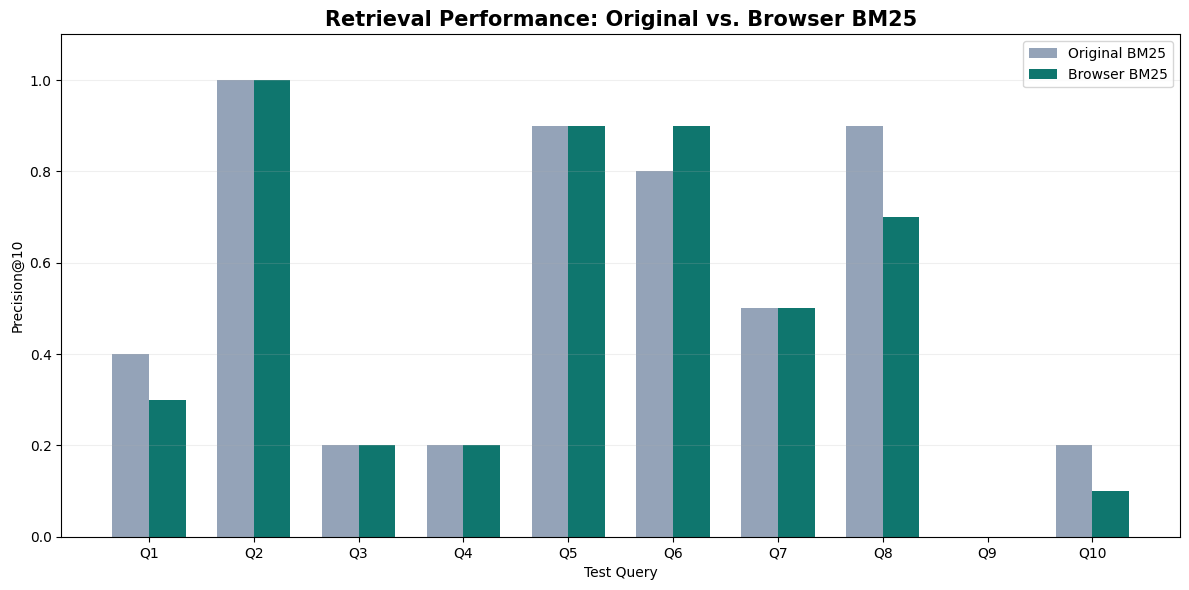

In [16]:

# Step 8B.6: Visualize retrieval performance

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(retrieval_comparison))
width = 0.35

ax.bar(
    x - width / 2,
    retrieval_comparison["Original_Precision_at_10"],
    width,
    label="Original BM25",
    color="#94A3B8"
)

ax.bar(
    x + width / 2,
    retrieval_comparison["Browser_Precision_at_10"],
    width,
    label="Browser BM25",
    color="#0F766E"
)

ax.set_xlabel("Test Query")
ax.set_ylabel("Precision@10")

ax.set_title(
    "Retrieval Performance: Original vs. Browser BM25",
    fontsize=15,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(retrieval_comparison.index)
ax.set_ylim(0, 1.1)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    "OTC_BM25_Performance_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Comparison of BM25 Retrieval and Faceted Browsing

Four information needs were selected from the original
retrieval evaluation to investigate the strengths and
limitations of structured faceted navigation.

The experiments examine:

- Q2: Simple symptom-based retrieval.
- Q4: Combining therapeutic use and dosage form.
- Q6: Boolean logic within a multi-valued facet.
- Q9: Vocabulary coverage and complex information needs.

The experiments reproduce the filtering behavior of
the deployed Streamlit application, which uses OR
within facets and AND across different facets.

Result counts, relevance, and limitations are examined
to compare structured browsing with BM25 retrieval.

In [17]:

# Step 8C.3: Reproduce faceted browsing experiments

# Convert intended-use tags into sets
use_tags = (
    df["Intended Use Tags"]
    .fillna("")
    .apply(lambda x: {
        tag.strip().lower()
        for tag in x.split(";")
        if tag.strip()
    })
)

# Q2: Cough relief
q2_faceted = df[
    use_tags.apply(lambda x: "cough" in x)
].copy()

# Q4: Pain AND Capsules
q4_faceted = df[
    use_tags.apply(lambda x: "pain" in x)
    & (df["Dosage Form Family"] == "Capsules")
].copy()

# Q6: Pain OR Fever
q6_faceted = df[
    use_tags.apply(
        lambda x: bool({"pain", "fever"} & x)
    )
].copy()

# Q9: Pain OR Upset stomach
q9_faceted = df[
    use_tags.apply(
        lambda x: bool({"pain", "upset stomach"} & x)
    )
].copy()

# Summarize results
facet_summary = pd.DataFrame({
    "Query_ID": ["Q2", "Q4", "Q6", "Q9"],
    "Facet_Conditions": [
        "cough",
        "pain AND Capsules",
        "pain OR fever",
        "pain OR upset stomach"
    ],
    "Medicines_Returned": [
        len(q2_faceted),
        len(q4_faceted),
        len(q6_faceted),
        len(q9_faceted)
    ],
    "Website_Results": [57, 6, 68, 71]
})

facet_summary["Matches_Website"] = (
    facet_summary["Medicines_Returned"]
    == facet_summary["Website_Results"]
)

display(facet_summary)

print("\nAll results match website:",
      facet_summary["Matches_Website"].all())

,Query_ID,Facet_Conditions,Medicines_Returned,Website_Results,Matches_Website
0,Q2,cough,57,57,True
1,Q4,pain AND Capsules,6,6,True
2,Q6,pain OR fever,68,68,True
3,Q9,pain OR upset stomach,71,71,True



All results match website: True



## Investigation of Boolean Logic in Faceted Browsing

The current faceted browser applies OR logic within
a facet and AND logic across different facets.

However, some information needs require multiple
values within the same facet to be satisfied
simultaneously.

This experiment compares OR and AND logic for:

- Q6: Pain and fever relief.
- Q9: Pain and upset stomach relief.

For Q9, upset stomach is used as an approximate
taxonomic representation of stomach irritation,
rather than an exact semantic equivalent.

The objective is to identify limitations in the
current interface and opportunities for improvement.

In [18]:

# Step 8C.4: Investigate AND versus OR logic

# Q6: Both pain AND fever
q6_and = df[
    use_tags.apply(
        lambda x: {"pain", "fever"}.issubset(x)
    )
].copy()

# Q9: Both pain AND upset stomach
q9_and = df[
    use_tags.apply(
        lambda x: {"pain", "upset stomach"}.issubset(x)
    )
].copy()

# Compare Boolean logic
boolean_comparison = pd.DataFrame({
    "Query_ID": ["Q6", "Q9"],
    "Conditions": [
        "Pain and fever",
        "Pain and upset stomach"
    ],
    "OR_Results": [
        len(q6_faceted),
        len(q9_faceted)
    ],
    "AND_Results": [
        len(q6_and),
        len(q9_and)
    ]
})

boolean_comparison["Partial_Matches"] = (
    boolean_comparison["OR_Results"]
    - boolean_comparison["AND_Results"]
)

display(boolean_comparison)

# Examine medicines satisfying only one condition
q6_partial = q6_faceted[
    ~q6_faceted["Item"].isin(q6_and["Item"])
]

print("\nQ6: Medicines satisfying only one condition")

display(q6_partial[
    ["Item", "Product", "Intended Use Tags", "Uses"]
])

print("\nQ9: Medicines satisfying both proxy conditions")

display(q9_and[
    ["Item", "Product", "Intended Use Tags", "Uses"]
])

,Query_ID,Conditions,OR_Results,AND_Results,Partial_Matches
0,Q6,Pain and fever,68,63,5
1,Q9,Pain and upset stomach,71,0,71



Q6: Medicines satisfying only one condition


,Item,Product,Intended Use Tags,Uses
56,57,Icy Hot Pro Pain Relief Cream,muscle; pain,Used to relieve or manage temporarily relieves minor muscle and joint pain.
57,58,Salonpas Pain Relieving Jet Spray,muscle; pain,Used to relieve or manage temporarily relieves minor muscle and joint aches.
58,59,Aspercreme Lidocaine Roll-On,muscle; pain,Used to relieve or manage temporarily relieves localized minor pain.
59,60,Bengay Lidocaine Cream,muscle; pain,Used to relieve or manage temporarily relieves minor muscle and joint pain.
249,250,Walgreens Triple Antibiotic with Pain Relief,burns; infection prevention; minor cuts; pain; scrapes,"Helps prevent infection and temporarily relieves pain/discomfort from minor cuts, \nscrapes and burns."



Q9: Medicines satisfying both proxy conditions


,Item,Product,Intended Use Tags,Uses



## Relevance Evaluation of Faceted Browsing

The first ten displayed results for Q2, Q6 and Q9,
and all six available results for Q4, are examined
against the original information needs.

Relevance is assessed using documented product
information rather than relying solely on facet
membership.

Precision is calculated using the actual number
of examined results. For Q4, the denominator is
six because only six products are returned.

In [19]:

# Step 8C.5: Prepare faceted relevance evaluation

facet_results = {
    "Q2": q2_faceted,
    "Q4": q4_faceted,
    "Q6": q6_faceted,
    "Q9": q9_faceted
}

facet_samples = []

for query_id, results in facet_results.items():

    sample = results.sort_values("Item").head(10).copy()

    sample["query_id"] = query_id

    sample["rank"] = range(1, len(sample) + 1)

    sample["relevance"] = np.nan

    facet_samples.append(sample)

facet_evaluation = pd.concat(
    facet_samples,
    ignore_index=True
)

# Display documents for relevance review

for query_id in facet_results:

    print("\n" + "=" * 80)
    print("QUERY:", query_id)

    need = queries.loc[
        queries["query_id"] == query_id, "need"
    ].iloc[0]

    print("Information need:", need)

    display(
        facet_evaluation.loc[
            facet_evaluation["query_id"] == query_id,
            [
                "rank",
                "Item",
                "Product",
                "Intended Use Tags",
                "Dosage Form",
                "Uses",
                "relevance"
            ]
        ]
    )

print("\nTotal documents to evaluate:",
      len(facet_evaluation))


QUERY: Q2
Information need: A person wants to find an OTC medicine that provides relief from coughing.


,rank,Item,Product,Intended Use Tags,Dosage Form,Uses,relevance
0,1,61,Vicks DayQuil Cold & Flu,cold; congestion; cough; fever; flu; pain,Liquid,"Relieves nasal congestion, cough, sore throat, headache, minor aches/pains \nand fever from cold/flu.",NaN
1,2,62,Vicks NyQuil Cold & Flu LiquiCaps,cold; cough; fever; flu; pain; runny nose; sneezing,Liquid-filled capsule,"Relieves cough, sore throat, headache, aches/pains, fever, \nrunny nose and sneezing associated with cold/flu.",NaN
2,3,63,Theraflu Flu Relief Max Strength Daytime,cold; cough; fever; flu; pain,Powder for oral solution,"Relieves headache, aches/pains, cough and sore throat from cold/flu; \nreduces fever.",NaN
3,4,64,Mucinex DM,chest congestion; cough,Extended-release tablet,Relieves cough and loosens phlegm to make coughs more productive.,NaN
4,5,65,Children's Dimetapp Cold & Cough,cold; congestion; cough; runny nose,Liquid,"Relieves nasal congestion, runny nose, cough, sneezing, \nitchy/watery eyes and nose/throat itching.",NaN
5,6,66,Children's Mucinex Cough,chest congestion; cough,Liquid,Relieves cough and chest congestion by loosening phlegm and \nreducing cough.,NaN
6,7,67,CVS Health Daytime Cold & Flu Relief,cold; congestion; cough; fever; flu; pain,Liquid,"Relieves cough, minor aches/pains, sore throat, headache and \nfever associated with cold/flu.",NaN
7,8,68,Walgreens Daytime Cold & Flu,cold; congestion; cough; fever; flu; pain,Softgel,"Relieves common cold/flu symptoms including cough, aches/pains,\nheadache, sore throat, fever and/or congestion depending on formulation.",NaN
8,9,69,Equate Daytime Cold & Flu,cold; congestion; cough; fever; flu; pain,Liquid,"Relieves aches/pains, headache, sore throat, fever, nasal congestion \nand cough from cold/flu.",NaN
9,10,70,Equate Nighttime Cold & Flu,cold; congestion; cough; fever; flu; pain; runny nose; sneezing,Liquid,"Relieves nighttime cold/flu symptoms including pain, fever, cough, \ncongestion/runny nose and sneezing.",NaN



QUERY: Q4
Information need: A person wants a pain relief medicine available in capsule form rather than tablets/liquids.


,rank,Item,Product,Intended Use Tags,Dosage Form,Uses,relevance
10,1,13,Tylenol Rapid Release Gels,fever; pain,Gelcap,Minor aches and fever,NaN
11,2,14,Advil Liqui-Gels,fever; pain,Liquid-filled capsule,Minor aches and fever,NaN
12,3,16,Advil Migraine,fever; pain,Liquid-filled capsule,Migraine headache relief,NaN
13,4,19,Aleve Liquid Gels,fever; pain,Liquid-filled capsule,Minor aches and fever,NaN
14,5,62,Vicks NyQuil Cold & Flu LiquiCaps,cold; cough; fever; flu; pain; runny nose; sneezing,Liquid-filled capsule,"Relieves cough, sore throat, headache, aches/pains, fever, \nrunny nose and sneezing associated with cold/flu.",NaN
15,6,68,Walgreens Daytime Cold & Flu,cold; congestion; cough; fever; flu; pain,Softgel,"Relieves common cold/flu symptoms including cough, aches/pains,\nheadache, sore throat, fever and/or congestion depending on formulation.",NaN



QUERY: Q6
Information need: A person wants one OTC medicine that can relieve both pain and fever.


,rank,Item,Product,Intended Use Tags,Dosage Form,Uses,relevance
16,1,1,Tylenol Extra Strength,fever; pain,Caplet,"Relieves minor aches/pains from cold, headache, backache, \narthritis, toothache, muscular aches and menstrual cramps; \nreduces fever.",NaN
17,2,2,Advil,fever; pain,Tablet/Caplet,"Relieves headache, toothache, backache, menstrual cramps, \ncold-related pain, muscular aches and arthritis pain; reduces fever.",NaN
18,3,3,Aleve Back & Muscle Pain,fever; pain,Caplet,"Relieves backache, muscular aches, arthritis pain, menstrual \ncramps, headache, toothache and cold-related pain; reduces fever.",NaN
19,4,4,Bayer Genuine Aspirin,fever; pain,Tablet,"Relieves headache, muscle pain, toothache, menstrual pain, \ncold-related pain/fever and arthritis pain.",NaN
20,5,5,Children's Tylenol,fever; pain,Chewable tablet,"Relieves pain from cold, flu, headache, sore throat and toothache; \nreduces fever.",NaN
21,6,6,Children's Motrin,fever; pain,Oral suspension,"Relieves pain from cold, flu, sore throat, headache and toothache; \nreduces fever.",NaN
22,7,7,Children's Motrin,fever; pain,Chewable tablet,"Relieves pain from cold, flu, sore throat, headache and toothache; \nreduces fever.",NaN
23,8,8,CVS Acetaminophen,fever; pain,Caplet,"Relieves common minor aches/pains including headache, backache, \narthritis, toothache, muscular aches and menstrual cramps; reduces \nfever.",NaN
24,9,9,Walgreens Ibuprofen 200,fever; pain,Caplet,"Relieves headache, muscular aches, arthritis pain, toothache, \nbackache, cold-related pain and menstrual cramps; reduces fever.",NaN
25,10,10,Equate Pain Reliever,fever; pain,Caplet,"Relieves common minor aches/pains including headache, \nbackache, arthritis, muscular aches, toothache and menstrual cramps; \nreduces fever.",NaN



QUERY: Q9
Information need: A person is experiencing pain and stomach irritation and wants relief from both conditions.


,rank,Item,Product,Intended Use Tags,Dosage Form,Uses,relevance
26,1,1,Tylenol Extra Strength,fever; pain,Caplet,"Relieves minor aches/pains from cold, headache, backache, \narthritis, toothache, muscular aches and menstrual cramps; \nreduces fever.",NaN
27,2,2,Advil,fever; pain,Tablet/Caplet,"Relieves headache, toothache, backache, menstrual cramps, \ncold-related pain, muscular aches and arthritis pain; reduces fever.",NaN
28,3,3,Aleve Back & Muscle Pain,fever; pain,Caplet,"Relieves backache, muscular aches, arthritis pain, menstrual \ncramps, headache, toothache and cold-related pain; reduces fever.",NaN
29,4,4,Bayer Genuine Aspirin,fever; pain,Tablet,"Relieves headache, muscle pain, toothache, menstrual pain, \ncold-related pain/fever and arthritis pain.",NaN
30,5,5,Children's Tylenol,fever; pain,Chewable tablet,"Relieves pain from cold, flu, headache, sore throat and toothache; \nreduces fever.",NaN
31,6,6,Children's Motrin,fever; pain,Oral suspension,"Relieves pain from cold, flu, sore throat, headache and toothache; \nreduces fever.",NaN
32,7,7,Children's Motrin,fever; pain,Chewable tablet,"Relieves pain from cold, flu, sore throat, headache and toothache; \nreduces fever.",NaN
33,8,8,CVS Acetaminophen,fever; pain,Caplet,"Relieves common minor aches/pains including headache, backache, \narthritis, toothache, muscular aches and menstrual cramps; reduces \nfever.",NaN
34,9,9,Walgreens Ibuprofen 200,fever; pain,Caplet,"Relieves headache, muscular aches, arthritis pain, toothache, \nbackache, cold-related pain and menstrual cramps; reduces fever.",NaN
35,10,10,Equate Pain Reliever,fever; pain,Caplet,"Relieves common minor aches/pains including headache, \nbackache, arthritis, muscular aches, toothache and menstrual cramps; \nreduces fever.",NaN



Total documents to evaluate: 36


In [20]:

# Step 8C.6: Save manual faceted relevance judgments

manual_facet_labels = {
    "Q2": [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    "Q4": [1, 1, 1, 1, 1, 1],
    "Q6": [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    "Q9": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
}

# Assign and validate judgments
for query_id, labels in manual_facet_labels.items():

    mask = facet_evaluation["query_id"] == query_id

    assert mask.sum() == len(labels)
    assert all(label in [0, 1] for label in labels)

    facet_evaluation.loc[mask, "relevance"] = labels

assert facet_evaluation["relevance"].isin([0, 1]).all()

facet_evaluation["relevance"] = (
    facet_evaluation["relevance"].astype(int)
)

# Calculate faceted precision
facet_performance = (
    facet_evaluation.groupby("query_id")
    .agg(
        Documents_Evaluated=("relevance", "size"),
        Relevant_Documents=("relevance", "sum"),
        Faceted_Precision=("relevance", "mean")
    )
    .reset_index()
)

# Add BM25 performance
facet_performance["BM25_Precision_at_10"] = (
    facet_performance["query_id"].map(browser_precision)
)

# Add total browser result counts
facet_performance["Total_Faceted_Results"] = (
    facet_performance["query_id"].map(
        facet_summary.set_index("Query_ID")["Medicines_Returned"]
    )
)

facet_performance["Difference"] = (
    facet_performance["Faceted_Precision"]
    - facet_performance["BM25_Precision_at_10"]
)

display(facet_performance.round(4))

print("\nTotal evaluated documents:", len(facet_evaluation))
print("Relevant documents:", facet_evaluation["relevance"].sum())
print("Missing judgments:", facet_evaluation["relevance"].isna().sum())

print("\nFaceted mean precision:",
      round(facet_performance["Faceted_Precision"].mean(), 4))

print("BM25 mean precision for the same four queries:",
      round(facet_performance["BM25_Precision_at_10"].mean(), 4))

print("\nAll relevance judgments validated successfully!")

,query_id,Documents_Evaluated,Relevant_Documents,Faceted_Precision,BM25_Precision_at_10,Total_Faceted_Results,Difference
0,Q2,10,10,1.0,1.0,57,0.0
1,Q4,6,6,1.0,0.2,6,0.8
2,Q6,10,10,1.0,0.9,68,0.1
3,Q9,10,0,0.0,0.0,71,0.0



Total evaluated documents: 36
Relevant documents: 26
Missing judgments: 0

Faceted mean precision: 0.75
BM25 mean precision for the same four queries: 0.525

All relevance judgments validated successfully!



## Comparison of Retrieval Performance

Across four selected information needs, faceted browsing
achieved a mean precision of 0.75, compared with 0.525
for BM25 retrieval.

The largest observed improvement occurred when the
information need combined therapeutic use and dosage form.

However, both approaches failed to satisfy Q9, revealing
limitations in vocabulary coverage and the collection.

The comparison is exploratory because it uses four selected
queries, different information representations, and unequal
result counts for Q4. Faceted results are ordered by item ID
rather than relevance score.

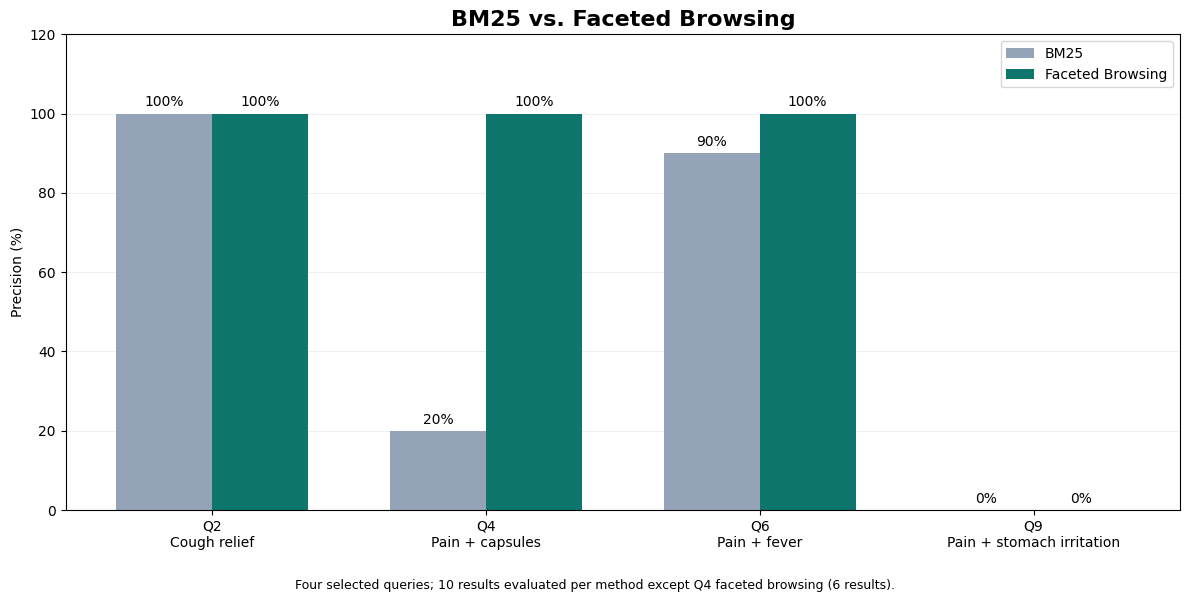

In [21]:

# Step 8C.7: Visualize BM25 vs faceted browsing

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(facet_performance))
width = 0.35

bars1 = ax.bar(
    x - width / 2,
    facet_performance["BM25_Precision_at_10"] * 100,
    width,
    label="BM25",
    color="#94A3B8"
)

bars2 = ax.bar(
    x + width / 2,
    facet_performance["Faceted_Precision"] * 100,
    width,
    label="Faceted Browsing",
    color="#0F766E"
)

ax.bar_label(bars1, fmt="%.0f%%", padding=3)
ax.bar_label(bars2, fmt="%.0f%%", padding=3)

ax.set_xticks(x)

ax.set_xticklabels([
    "Q2\nCough relief",
    "Q4\nPain + capsules",
    "Q6\nPain + fever",
    "Q9\nPain + stomach irritation"
])

ax.set_ylabel("Precision (%)")

ax.set_title(
    "BM25 vs. Faceted Browsing",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylim(0, 120)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    "Four selected queries; 10 results evaluated per method "
    "except Q4 faceted browsing (6 results).",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    "OTC_BM25_vs_Faceted_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Export Retrieval Evaluation Results

The following files document the retrieval experiments:

- Original information needs and search queries.
- Original and additional relevance judgments.
- BM25 ranked results and performance metrics.
- Faceted browsing relevance judgments and performance.
- Boolean logic comparison.
- Retrieval performance visualizations.

These files support reproducibility and provide evidence
for the findings discussed in the final project report.

In [22]:

# Step 8D.1: Export retrieval evaluation results

import os
import zipfile
from google.colab import files

output_folder = "OTC_Retrieval_Results"

os.makedirs(output_folder, exist_ok=True)

# Define files to export
export_tables = {
    "OTC_Test_Queries.csv": queries,
    "OTC_Original_Relevance_Judgments.csv": judgments,
    "OTC_Additional_Relevance_Judgments.csv": new_judgments,
    "OTC_Combined_Relevance_Judgments.csv": all_judgments,
    "OTC_Browser_BM25_Results.csv": evaluated_results,
    "OTC_BM25_Performance_Comparison.csv":
        retrieval_comparison.reset_index(),
    "OTC_Faceted_Browser_Results.csv": facet_summary,
    "OTC_Boolean_Logic_Comparison.csv": boolean_comparison,
    "OTC_Faceted_Relevance_Judgments.csv": facet_evaluation,
    "OTC_BM25_vs_Faceted_Performance.csv": facet_performance
}

# Export all CSV files
for filename, table in export_tables.items():
    table.to_csv(
        os.path.join(output_folder, filename),
        index=False
    )

# Include visualizations
import shutil

figures = [
    "OTC_BM25_Performance_Comparison.png",
    "OTC_BM25_vs_Faceted_Comparison.png"
]

for figure in figures:
    assert os.path.exists(figure), f"Missing figure: {figure}"
    shutil.copy(figure, output_folder)

# Create ZIP archive
zip_name = "OTC_Retrieval_Evaluation_Results.zip"

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for filename in sorted(os.listdir(output_folder)):
        zipf.write(
            os.path.join(output_folder, filename),
            arcname=filename
        )

# Verify exported files
with zipfile.ZipFile(zip_name, "r") as zipf:
    exported_files = zipf.namelist()

    print("Total exported files:", len(exported_files))

    for filename in exported_files:
        print("✓", filename)

print("\nRetrieval evaluation successfully exported!")

files.download(zip_name)

Total exported files: 12
✓ OTC_Additional_Relevance_Judgments.csv
✓ OTC_BM25_Performance_Comparison.csv
✓ OTC_BM25_Performance_Comparison.png
✓ OTC_BM25_vs_Faceted_Comparison.png
✓ OTC_BM25_vs_Faceted_Performance.csv
✓ OTC_Boolean_Logic_Comparison.csv
✓ OTC_Browser_BM25_Results.csv
✓ OTC_Combined_Relevance_Judgments.csv
✓ OTC_Faceted_Browser_Results.csv
✓ OTC_Faceted_Relevance_Judgments.csv
✓ OTC_Original_Relevance_Judgments.csv
✓ OTC_Test_Queries.csv

Retrieval evaluation successfully exported!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>